# Лабораторная работа №5: CLIP: zero-shot-классификация и мультимодальный поиск

**Версия:** студенческая  
**Курс:** «Современное компьютерное зрение»

> Сначала выполните notebook в режиме `FAST_DEV_RUN=True`, затем запускайте полный эксперимент. Сохраняйте метрики и checkpoints в `artifacts/`.


## Цели обучения

После работы студент должен уметь:

- Сравнить prompt templates в zero-shot classification.
- Построить text-to-image retrieval.
- Дообучить projection head и оценить Recall@K.


## Теоретическая часть

CLIP обучает image encoder и text encoder в общем нормированном пространстве. Zero-shot logits пропорциональны cosine similarity между изображением и текстовыми шаблонами классов.

![CLIP](https://raw.githubusercontent.com/openai/CLIP/main/CLIP.png)


### Математическая постановка

$$s(x,t)=\frac{f_I(x)^\top f_T(t)}{\|f_I(x)\|\|f_T(t)\|},\qquad p(c\mid x)=\operatorname{softmax}(s(x,t_c)/\tau).$$
Для retrieval используются Recall@K и median rank.


### Материалы

- [OpenCLIP](https://github.com/mlfoundations/open_clip)
- [CLIP paper](https://arxiv.org/abs/2103.00020)

Ссылки даны как дополнительный материал. При изменении API сверяйтесь с актуальной официальной документацией и фиксируйте версии зависимостей.


## Практическое задание

1. Сравнить prompt templates в zero-shot classification.
2. Построить text-to-image retrieval.
3. Дообучить projection head и оценить Recall@K.

**Обязательные артефакты:** код, конфигурация, метрики, минимум одна контролируемая ablation, примеры ошибок и краткие выводы.


### Профиль вычислений

- **Основной режим:** OpenCLIP ViT-B-32 frozen/малый projection head.
- **Ограничение данных:** CIFAR-10 или до 5 000 пар.
- **Fallback:** CPU на 500 объектах.
- Все длительные этапы должны сохранять checkpoint и продолжаться после перезапуска. Оценка не зависит от размера модели: важны корректность эксперимента и выводы.


**Оценивание.** Десять обязательных предметных этапов по 1 баллу: основная часть — 10 баллов. Творческий бонус — отдельно 1 балл, не заменяет обязательные этапы. Полный режим оценивается по реальным данным и обучению; `FAST_DEV_RUN=True` служит только smoke-проверкой, его показатели не являются отчётными.


## Реализация


In [1]:
# Базовое воспроизводимое окружение
from pathlib import Path
import json, os, random, time
import numpy as np

SEED = 42
FAST_DEV_RUN = False  # True — только проверка связности на уменьшенной выборке; не отчётный результат
# Отдельная подпапка: в artifacts/ лежат результаты лабораторной №1, в artifacts/lab2–lab4 — №2–№4.
ARTIFACTS = Path(os.getenv("CV_ARTIFACTS", "artifacts/lab5"))
ARTIFACTS.mkdir(parents=True, exist_ok=True)
random.seed(SEED); np.random.seed(SEED)
try:
    import torch
    torch.manual_seed(SEED)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
    DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
except ImportError:
    torch = None
    DEVICE = "cpu"
# Датасеты курса лежат в общем каталоге <корень курса>/data:
# notebook выполняется из labs/lab_XX_*/, поэтому корень курса — cwd.parent.parent.
# Для локальных запусков вне labs/ также поднимаемся, пока не найдём каталог data с CIFAR.
_CANDIDATES = [Path.cwd().parent.parent / "data", Path.cwd().parent / "data", Path.cwd() / "data"]
DATA_ROOT = Path(os.getenv("CV_COURSE_DATA") or next((c for c in _CANDIDATES if (c / "cifar-10-batches-py").exists()), _CANDIDATES[0]))
DATA_ROOT.mkdir(parents=True, exist_ok=True)
print({"device": DEVICE, "fast_dev_run": FAST_DEV_RUN, "data_root": str(DATA_ROOT), "artifacts": str(ARTIFACTS)})


{'device': 'cuda', 'fast_dev_run': False, 'data_root': 'c:\\Users\\bogom\\OneDrive\\Документы\\PSY\\6 курс\\МО\\data', 'artifacts': 'artifacts\\lab5'}


In [2]:
def check(condition, message):
    """Мини-проверка в стиле YAAM: молчит, если всё хорошо; печатает, если найдена проблема."""
    if condition:
        print(f"✔ {message}")
    else:
        print(f"✘ ВНИМАНИЕ: {message}")

### Задание 1. Данные и предобученный CLIP

*Вес: 1 балл.*

**Постановка.** Индекс поиска и обучающие пары должны состоять из разных изображений.

Выполните следующие действия:
1. Загрузите CIFAR-10 train/test и OpenCLIP ViT-B-32.
2. Определите список классов и независимый test-загрузчик.

**Результат.** Объекты model, train_pairs, ds, classes, loader.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


CLIP (Contrastive Language–Image Pre-training) — это нейросеть от OpenAI (2021), которая умеет сравнивать картинки и тексты. Она переводит и то и другое в векторы одного пространства, поэтому картинку можно напрямую сопоставить с фразой.

**Что делали**: загрузили CIFAR-10 и CLIP ViT-B-32, заморозили CLIP. Взяли 5000 train-картинок (по 500 на класс) и все 10 000 test-картинок, сделали загрузчик без перемешивания.<br>
**Зачем**: подготовить данные и модель. Train и test не пересекаются, поэтому обучение и оценка идут на разных картинках.<br>
**Результат**: объекты model, train_pairs, ds, classes, loader и файл config.json. Все проверки ✔.

In [3]:
# Задание 1. Данные и предобученный CLIP
import subprocess, sys
from torch.utils.data import DataLoader, Subset
import torchvision

try:
    import open_clip
except ImportError:  # open_clip_torch не входит в базовое окружение курса
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "open_clip_torch"])
    import open_clip

# 1. OpenCLIP ViT-B-32: веса заморожены, дальше обучаются только малые проекции
CLIP_ARCH, CLIP_PRETRAINED = "ViT-B-32", "laion2b_s34b_b79k"
model, _, preprocess = open_clip.create_model_and_transforms(CLIP_ARCH, pretrained=CLIP_PRETRAINED)
tokenizer = open_clip.get_tokenizer(CLIP_ARCH)
model = model.to(DEVICE).eval()
for p in model.parameters():
    p.requires_grad_(False)

# Бюджет: до 5 000 обучающих пар; на CPU и в FAST_DEV_RUN — 500 объектов (fallback из профиля вычислений)
SMALL = FAST_DEV_RUN or DEVICE == "cpu"
N_TRAIN_PAIRS = 500 if SMALL else 5000
N_TEST = 500 if SMALL else 10000
BATCH_SIZE = 256

# CIFAR-10: обучающие пары берутся только из train, индекс поиска — только из test
train_full = torchvision.datasets.CIFAR10(root=DATA_ROOT, train=True, download=True, transform=preprocess)
test_full = torchvision.datasets.CIFAR10(root=DATA_ROOT, train=False, download=True, transform=preprocess)
classes = list(train_full.classes)

def stratified_indices(targets, n_total, seed):
    """Поровну объектов каждого класса — чтобы малая выборка не перекосила метрики по классам."""
    rng = np.random.default_rng(seed)
    targets = np.asarray(targets)
    per_class = n_total // len(classes)
    idx = [rng.choice(np.flatnonzero(targets == c), per_class, replace=False) for c in range(len(classes))]
    return np.sort(np.concatenate(idx))

train_idx = stratified_indices(train_full.targets, N_TRAIN_PAIRS, SEED)
test_idx = np.arange(len(test_full)) if N_TEST >= len(test_full) else stratified_indices(test_full.targets, N_TEST, SEED + 1)

# 2. train_pairs: (изображение, метка) — подпись строится из метки при обучении проекций
train_pairs = Subset(train_full, train_idx.tolist())
# ds и loader: независимый test без перемешивания, порядок фиксирован для индекса поиска
ds = Subset(test_full, test_idx.tolist())
loader = DataLoader(ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=0, pin_memory=(DEVICE == "cuda"))
test_labels = np.asarray(test_full.targets)[test_idx]

config = {
    "clip_arch": CLIP_ARCH, "clip_pretrained": CLIP_PRETRAINED, "frozen_backbone": True,
    "seed": SEED, "device": DEVICE, "fast_dev_run": FAST_DEV_RUN,
    "n_train_pairs": len(train_pairs), "n_test": len(ds), "batch_size": BATCH_SIZE, "classes": classes,
}
(ARTIFACTS / "config.json").write_text(json.dumps(config, ensure_ascii=False, indent=2), encoding="utf-8")

check(len(classes) == 10, f"10 классов CIFAR-10: {classes}")
check(train_full.train and not test_full.train, "обучающие пары из train-сплита, индекс поиска из test-сплита — изображения не пересекаются")
check(len(set(np.bincount(np.asarray(train_full.targets)[train_idx]))) == 1, f"train_pairs сбалансированы: {len(train_pairs)} пар")
check(not loader.sampler.__class__.__name__.startswith("Random"), f"test-загрузчик без перемешивания: {len(ds)} изображений")
print({"n_train_pairs": len(train_pairs), "n_test": len(ds), "image_size": tuple(ds[0][0].shape), "small_budget": SMALL})

c:\Users\bogom\OneDrive\Документы\PSY\6 курс\МО\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


✔ 10 классов CIFAR-10: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
✔ обучающие пары из train-сплита, индекс поиска из test-сплита — изображения не пересекаются
✔ train_pairs сбалансированы: 5000 пар
✔ test-загрузчик без перемешивания: 10000 изображений
{'n_train_pairs': 5000, 'n_test': 10000, 'image_size': (3, 224, 224), 'small_budget': False}


### Задание 2. Текстовые прототипы классов

*Вес: 1 балл.*

**Постановка.** Нормализация эмбеддингов превращает скалярное произведение в cosine similarity.

Выполните следующие действия:
1. Создайте несколько шаблонов класса.
2. Закодируйте и нормируйте текстовые прототипы.

**Результат.** templates и функция text_prototypes.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


**Что делали**: задали 5 шаблонов фраз («a photo of a {}.» и т. д.), подставили 10 классов, закодировали текст CLIP-ом и нормировали векторы. Добавили ансамбль (среднее 5 шаблонов).<br>
**Зачем**: получить вектор-эталон для каждого класса, чтобы сравнивать с ним картинки без обучения. Получилось шесть наборов по 10 эталонов<br>
**Результат**: 6 (пять шаблонов плюс ансамбль, среднее 5 векторов) матриц 10 (число классов) × 512 (длина вектора CLIP). Самая близкая пара классов — automobile/truck (косинус 0.88).

In [4]:
# Задание 2. Текстовые прототипы классов
import torch.nn.functional as F

# 1. Шаблоны фиксируются заранее, до любых измерений на test; {} заменяется именем класса
templates = {
    "bare": "{}",
    "photo": "a photo of a {}.",
    "low_res": "a low resolution photo of a {}.",
    "blurry": "a blurry photo of a {}.",
    "cifar": "a photo of a {}, a type of object in the CIFAR-10 dataset.",
}

@torch.no_grad()
def text_prototypes(template, head=None):
    """Нормированные текстовые прототипы классов, форма (10, d).

    template — строка-шаблон или список шаблонов (тогда эмбеддинги усредняются: prompt ensembling);
    head — необязательная обучаемая текстовая проекция (используется после задания 7).
    """
    template_list = [template] if isinstance(template, str) else list(template)
    protos = []
    for name in classes:
        tokens = tokenizer([t.format(name) for t in template_list]).to(DEVICE)
        emb = F.normalize(model.encode_text(tokens).float(), dim=-1)  # каждый вариант подписи — на единичную сферу
        protos.append(emb.mean(dim=0))
    protos = torch.stack(protos)
    if head is not None:
        protos = head(protos)
    # Итоговая нормировка: скалярное произведение с нормированным изображением = cosine similarity
    return F.normalize(protos, dim=-1)

# 2. Прототипы для каждого шаблона и для ансамбля всех шаблонов
prototypes = {name: text_prototypes(t) for name, t in templates.items()}
prototypes["ensemble"] = text_prototypes(list(templates.values()))

norms = torch.stack([p.norm(dim=-1) for p in prototypes.values()])
check(torch.allclose(norms, torch.ones_like(norms), atol=1e-4), "все прототипы имеют единичную норму")
check(all(p.shape == (len(classes), prototypes["photo"].shape[1]) for p in prototypes.values()),
      f"прототипы формы ({len(classes)}, {prototypes['photo'].shape[1]}) для {len(prototypes)} вариантов")
# Косинусное сходство между прототипами классов: насколько различимы классы в текстовом пространстве
sim = (prototypes["photo"] @ prototypes["photo"].T).cpu().numpy()
off = sim[~np.eye(len(classes), dtype=bool)]
i, j = np.unravel_index(np.where(np.eye(len(classes), dtype=bool), -1, sim).argmax(), sim.shape)
print({"templates": list(templates), "mean_cos_between_classes": round(float(off.mean()), 3),
       "closest_pair": (classes[i], classes[j], round(float(sim[i, j]), 3))})

✔ все прототипы имеют единичную норму
✔ прототипы формы (10, 512) для 6 вариантов
{'templates': ['bare', 'photo', 'low_res', 'blurry', 'cifar'], 'mean_cos_between_classes': 0.774, 'closest_pair': ('automobile', 'truck', 0.881)}


1. Задается 5 шаблонов
```
"a photo of a {}."  +  cat  →  "a photo of a cat."
```

2. Превращаем фразы в векторы.
```
фраза  →  токены  →  текстовый энкодер CLIP  →  вектор из 512 чисел  →  нормировка до длины 1
```

### Задание 3. Zero-shot классификация

*Вес: 1 балл.*

**Постановка.** Подбор словесного шаблона влияет на прогноз без дополнительного обучения.

Выполните следующие действия:
1. Для каждого заранее заданного шаблона предскажите test-классы по сходству.
2. Зафиксируйте accuracy всех шаблонов без выбора лучшей модели по test.

**Результат.** zero_shot.json с фактической точностью шаблонов.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


Шестым вектором является ensemble, он усредняет пять векторов шаблона

**Что делали**: закодировали 10 000 test-картинок, сравнили каждую с прототипами и выбрали ближайший класс. Посчитали accuracy для каждого из 6 вариантов, лучший по test не выбирали.<br>
Процесс классификации и подсчета accuracy:
1. Для одной картинки происходит 6 независимых классификаций:
```text
набор bare:      сравнение с 10 эталонами → ближайший → ответ 1
набор photo:     сравнение с 10 эталонами → ближайший → ответ 2
набор low_res:   сравнение с 10 эталонами → ближайший → ответ 3
набор blurry:    сравнение с 10 эталонами → ближайший → ответ 4
набор cifar:     сравнение с 10 эталонами → ближайший → ответ 5
набор ensemble:  сравнение с 10 эталонами → ближайший → ответ 6
```
2. Ответы могут различаться. Например, для размытой кошки bare может сказать dog, а photo — cat.
3. Потом для каждого набора отдельно считается accuracy по всем 10 000 картинкам. Отсюда 6 чисел: 0.717, 0.937 и т. д.

**Зачем**: проверить, как формулировка текста влияет на прогноз без обучения.<br>
**Результат**: zero_shot.json. photo 0.937, bare всего 0.717, остальные 0.927–0.934. Главная ошибка — cat → dog (82 раза).

In [7]:
# Задание 3. Zero-shot классификация
from tqdm.auto import tqdm

@torch.no_grad()
def encode_images(data_loader, desc="encode"):
    """Нормированные эмбеддинги изображений замороженного CLIP и их метки, в порядке загрузчика."""
    feats, labels = [], []
    for x, y in tqdm(data_loader, desc=desc):
        with torch.autocast(device_type="cuda", enabled=(DEVICE == "cuda")):
            f = model.encode_image(x.to(DEVICE, non_blocking=True))
        feats.append(F.normalize(f.float(), dim=-1).cpu())
        labels.append(y)
    return torch.cat(feats), torch.cat(labels)

# Кодирование 10 000 изображений — самый долгий шаг: признаки кешируются и переиспользуются после перезапуска
TEST_FEATS_PATH = ARTIFACTS / "test_image_features.pt"
if TEST_FEATS_PATH.exists() and torch.load(TEST_FEATS_PATH)["test_idx"] == test_idx.tolist():
    cached = torch.load(TEST_FEATS_PATH)
    test_feats, test_targets = cached["features"], cached["labels"]
    print(f"признаки test загружены из {TEST_FEATS_PATH}")
else:
    test_feats, test_targets = encode_images(loader, desc="test images")
    torch.save({"features": test_feats, "labels": test_targets, "test_idx": test_idx.tolist()}, TEST_FEATS_PATH)

# 1. Прогноз по каждому заранее заданному шаблону: класс с максимальным cosine similarity
zero_shot_preds, zero_shot_acc = {}, {}
for name, protos in prototypes.items():
    sims = test_feats @ protos.cpu().T          # (N, 10) — косинусы, т.к. обе стороны нормированы
    preds = sims.argmax(dim=1)
    zero_shot_preds[name] = preds
    zero_shot_acc[name] = float((preds == test_targets).float().mean())

# Поклассовая точность и самая частая путаница для стандартного шаблона "photo"
preds_photo = zero_shot_preds["photo"].numpy()
y_true = test_targets.numpy()
per_class_acc = {c: float((preds_photo[y_true == k] == k).mean()) for k, c in enumerate(classes)}
confusion = np.zeros((len(classes), len(classes)), dtype=int)
np.add.at(confusion, (y_true, preds_photo), 1)
off_diag = np.where(np.eye(len(classes), dtype=bool), 0, confusion)
t, p = np.unravel_index(off_diag.argmax(), off_diag.shape)

# 2. Фиксируем accuracy ВСЕХ шаблонов; лучший по test не выбирается — "photo" остаётся базовым шаблоном
zero_shot = {
    "n_test": len(test_targets),
    "fast_dev_run": FAST_DEV_RUN,
    "templates": {**templates, "ensemble": "mean of all templates above"},
    "accuracy": zero_shot_acc,
    "reference_template": "photo",
    "selection_note": "шаблоны заданы до оценки; accuracy на test только фиксируется, лучший шаблон по test не выбирается",
    "per_class_accuracy_photo": per_class_acc,
    "top_confusion_photo": {"true": classes[t], "pred": classes[p], "count": int(off_diag[t, p])},
}
(ARTIFACTS / "zero_shot.json").write_text(json.dumps(zero_shot, ensure_ascii=False, indent=2), encoding="utf-8")

check(len(test_targets) == len(ds) and (test_targets.numpy() == test_labels).all(), "признаки и метки соответствуют test в фиксированном порядке")
check(set(zero_shot_acc) == set(prototypes), f"accuracy зафиксирована для всех {len(zero_shot_acc)} вариантов шаблонов")
check(min(zero_shot_acc.values()) > 1 / len(classes), "все шаблоны лучше случайного угадывания (10%)")
for name, acc in zero_shot_acc.items():
    print(f"{name:>9}: accuracy = {acc:.4f}")
print({"worst_class_photo": min(per_class_acc, key=per_class_acc.get), "top_confusion_photo": zero_shot["top_confusion_photo"]})

признаки test загружены из artifacts\lab5\test_image_features.pt
✔ признаки и метки соответствуют test в фиксированном порядке
✔ accuracy зафиксирована для всех 6 вариантов шаблонов
✔ все шаблоны лучше случайного угадывания (10%)
     bare: accuracy = 0.7173
    photo: accuracy = 0.9368
  low_res: accuracy = 0.9313
   blurry: accuracy = 0.9305
    cifar: accuracy = 0.9343
 ensemble: accuracy = 0.9273
{'worst_class_photo': 'cat', 'top_confusion_photo': {'true': 'cat', 'pred': 'dog', 'count': 82}}


```text
картинка  →  CLIP  →  вектор картинки (один и тот же для всех шаблонов)
                              │
                              │  сравнение (косинус)
                              ▼
шаблон + 10 классов  →  10 фраз  →  CLIP  →  10 прототипов
                                                    │
                                                    ▼
                                    класс с максимальным косинусом = ответ
```

|№|	Название	|Шаблон|
|:---|	:---|:---|
|1	|bare|	{}|
|2	|photo|	a photo of a {}.|
|3	|low_res|	a low resolution photo of a {}.|
|4	|blurry|	a blurry photo of a {}.|
|5	|cifar|	a photo of a {}, a type of object in the CIFAR-10 dataset.|


### Задание 4. Векторный индекс изображений

*Вес: 1 балл.*

**Постановка.** Текстовый поиск опирается на сохранённые признаки реальных изображений.

Выполните следующие действия:
1. Извлеките нормированные эмбеддинги test и метки.
2. Вычислите top-10 для текстового запроса.

**Результат.** clip_index.pt и retrieval.json с индексами test.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


Нормированные эмбеддинги test:
- Эмбеддинг — вектор из 512 чисел, в который CLIP превращает картинку. Это её описание в виде чисел.
- Test — 10 000 тестовых картинок CIFAR-10. Модель их не видела при обучении проекций.
- Нормированный — вектор приведён к длине 1: каждое число поделено на длину вектора. Направление сохраняется, а длина больше не влияет на сравнение.

По текстовому запросу находим топ 10 картинок.

**Что делали**: сохранили нормированные векторы test-картинок с метками, написали функции поиска, нашли top-10 картинок для запроса каждого класса. 10 запросов по одному на класс (a photo of a airplane. a photo of a automobile. и т.д.). Для каждого запроса нашлись top-10 картинок<br>
**Зачем**: построить поиск картинок по тексту.<br>
**Результат**: clip_index.pt и retrieval.json. По запросу horse найдено 9 лошадей и 1 олень.

In [8]:
# Задание 4. Векторный индекс изображений
K = 10
QUERY_TEMPLATE = templates["photo"]  # шаблон запроса фиксирован заранее, как базовый в задании 3

# 1. Индекс: нормированные эмбеддинги реальных test-изображений (из задания 3) + метки + исходные номера в CIFAR-10 test
index_feats, index_labels = test_feats, test_targets
clip_index = {
    "features": index_feats,                 # (N, 512), каждая строка единичной нормы
    "labels": index_labels,                  # (N,) истинные классы
    "test_idx": torch.as_tensor(test_idx),   # позиция в индексе -> номер изображения в CIFAR-10 test
    "classes": classes,
    "clip_arch": CLIP_ARCH, "clip_pretrained": CLIP_PRETRAINED,
}
torch.save(clip_index, ARTIFACTS / "clip_index.pt")

@torch.no_grad()
def encode_query(text, head=None):
    """Нормированный эмбеддинг произвольного текстового запроса (head — обучаемая проекция после задания 7)."""
    emb = model.encode_text(tokenizer([text]).to(DEVICE)).float()
    emb = F.normalize(emb, dim=-1)
    if head is not None:
        emb = F.normalize(head(emb), dim=-1)
    return emb.squeeze(0).cpu()

def search(query_emb, feats, k=K):
    """Top-k изображений индекса по cosine similarity: (позиции в индексе, сходства)."""
    scores = feats @ query_emb
    top = torch.topk(scores, k)
    return top.indices, top.values

# 2. Top-10 для текстового запроса каждого класса
retrieval = {"k": K, "query_template": QUERY_TEMPLATE, "n_index": len(index_labels), "queries": {}}
for c_idx, name in enumerate(classes):
    query = QUERY_TEMPLATE.format(name)
    pos, scores = search(encode_query(query), index_feats)
    retrieval["queries"][name] = {
        "query": query,
        "index_positions": pos.tolist(),                  # строки clip_index["features"]
        "test_indices": test_idx[pos.numpy()].tolist(),   # номера изображений в CIFAR-10 test
        "retrieved_labels": [classes[l] for l in index_labels[pos].tolist()],
        "scores": [round(float(s), 4) for s in scores],
    }
(ARTIFACTS / "retrieval.json").write_text(json.dumps(retrieval, ensure_ascii=False, indent=2), encoding="utf-8")

reloaded = torch.load(ARTIFACTS / "clip_index.pt")
check(torch.allclose(reloaded["features"].norm(dim=-1), torch.ones(len(index_labels)), atol=1e-3), f"индекс из {len(index_labels)} нормированных эмбеддингов сохранён в clip_index.pt")
check(all(len(set(q["index_positions"])) == K for q in retrieval["queries"].values()), f"для каждого из {len(classes)} запросов найдено {K} разных изображений")
example = retrieval["queries"]["horse"]
print({"query": example["query"], "test_indices": example["test_indices"], "retrieved_labels": example["retrieved_labels"]})

✔ индекс из 10000 нормированных эмбеддингов сохранён в clip_index.pt
✔ для каждого из 10 запросов найдено 10 разных изображений
{'query': 'a photo of a horse.', 'test_indices': [3461, 8074, 6678, 1828, 1398, 5221, 468, 8865, 3962, 6657], 'retrieved_labels': ['horse', 'horse', 'horse', 'horse', 'horse', 'horse', 'horse', 'horse', 'deer', 'horse']}


### Задание 5. Релевантность поиска по классам

*Вес: 1 балл.*

**Постановка.** Precision@10 и recall@10 требуют фиксированного определения релевантности.

Выполните следующие действия:
1. Задайте релевантность как совпадение с классом запроса.
2. Вычислите метрики поиска для каждого класса.

**Результат.** retrieval_report.json с фактическими значениями.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


**Релевантность поиска по классам**

- **Что делали**: договорились считать находку правильной, если её класс совпадает с классом запроса. Посчитали precision@10 и recall@10 по каждому классу.
- **Зачем**: измерить качество поиска числами.
- **Результат**: retrieval_report.json. Средняя precision@10 = 0.99, у 9 классов 1.0, у horse 0.9. Recall@10 ≈ 0.01, это его потолок.

In [9]:
# Задание 5. Релевантность поиска по классам
# 1. Фиксированное определение: найденное изображение релевантно, если его истинный класс совпадает с классом запроса
def is_relevant(retrieved_labels, query_class):
    return retrieved_labels == query_class

def retrieval_metrics(feats, labels, query_embs, k=K):
    """Precision@k и recall@k для запроса каждого класса.

    feats — (N, d) нормированные эмбеддинги индекса; labels — (N,) истинные классы;
    query_embs — (10, d) нормированные эмбеддинги запросов, строка c — запрос класса c.
    """
    per_class = {}
    for c_idx, name in enumerate(classes):
        pos, _ = search(query_embs[c_idx], feats, k)
        rel = is_relevant(labels[pos], c_idx)
        n_rel_total = int((labels == c_idx).sum())       # сколько изображений класса вообще есть в индексе
        hits = int(rel.sum())
        per_class[name] = {
            "hits": hits,
            "precision@k": hits / k,                     # доля релевантных среди k найденных
            "recall@k": hits / n_rel_total,              # доля найденных среди всех релевантных
            "n_relevant_in_index": n_rel_total,
        }
    mean = {m: float(np.mean([v[m] for v in per_class.values()])) for m in ("precision@k", "recall@k")}
    return per_class, mean

# 2. Метрики исходного (замороженного) CLIP: запросы — те же фразы "a photo of a {класс}.", что в задании 4
query_embs_base = torch.stack([encode_query(QUERY_TEMPLATE.format(name)) for name in classes])
base_per_class, base_mean = retrieval_metrics(index_feats, index_labels, query_embs_base, K)

retrieval_report = {
    "k": K,
    "relevance": "найденное изображение релевантно, если его истинный класс CIFAR-10 совпадает с классом запроса",
    "query_template": QUERY_TEMPLATE,
    "n_index": len(index_labels),
    "fast_dev_run": FAST_DEV_RUN,
    "per_class": base_per_class,
    "mean": base_mean,
    "recall_note": f"recall@{K} ограничен сверху {K}/n_relevant: при ~{int(np.mean([v['n_relevant_in_index'] for v in base_per_class.values()]))} изображениях класса максимум ≈ {K / np.mean([v['n_relevant_in_index'] for v in base_per_class.values()]):.4f}",
}
(ARTIFACTS / "retrieval_report.json").write_text(json.dumps(retrieval_report, ensure_ascii=False, indent=2), encoding="utf-8")

# Согласованность с top-10, сохранёнными в задании 4
check(all(base_per_class[n]["hits"] == retrieval["queries"][n]["retrieved_labels"].count(n) for n in classes),
      "метрики совпадают с top-10 из retrieval.json")
check(all(0 <= v["precision@k"] <= 1 for v in base_per_class.values()), f"precision@{K} посчитана для всех {len(classes)} классов")
for name, v in base_per_class.items():
    print(f"{name:>10}: precision@{K} = {v['precision@k']:.2f}, recall@{K} = {v['recall@k']:.4f}")
print({"mean_precision@10": round(base_mean["precision@k"], 4), "mean_recall@10": round(base_mean["recall@k"], 4)})

✔ метрики совпадают с top-10 из retrieval.json
✔ precision@10 посчитана для всех 10 классов
  airplane: precision@10 = 1.00, recall@10 = 0.0100
automobile: precision@10 = 1.00, recall@10 = 0.0100
      bird: precision@10 = 1.00, recall@10 = 0.0100
       cat: precision@10 = 1.00, recall@10 = 0.0100
      deer: precision@10 = 1.00, recall@10 = 0.0100
       dog: precision@10 = 1.00, recall@10 = 0.0100
      frog: precision@10 = 1.00, recall@10 = 0.0100
     horse: precision@10 = 0.90, recall@10 = 0.0090
      ship: precision@10 = 1.00, recall@10 = 0.0100
     truck: precision@10 = 1.00, recall@10 = 0.0100
{'mean_precision@10': 0.99, 'mean_recall@10': 0.0099}


Проверяется точность поиска по тексту. По запросу «a photo of a horse.» лошадь релевантна, олень нет.

precision@10 — какая доля найденного правильная: попадания / 10<br>
recall@10 какую долю всех картинок класса мы нашли: попадания / 1000


### Задание 6. Данные для обучаемой проекции

*Вес: 1 балл.*

**Постановка.** Одинаковые подписи в мини-партии не являются отрицательными парами. Проекция обучается по классовым прототипам.

Выполните следующие действия:
1. Создайте две линейные проекции и инициализируйте тождественно.
2. Подготовьте независимые train-пары и optimizer.

**Результат.** image_head, text_head и train_loader.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


**Данные для обучаемой проекции**

- **Что делали**: создали две матрицы 512 × 512 (image_head, text_head) с единичной инициализацией. Закодировали train-картинки и разделили их на 4500 для обучения и 500 для контроля. Настроили Adam.
- **Зачем**: подготовить лёгкую подстройку CLIP под CIFAR, не трогая сам CLIP. Единичная матрица гарантирует, что до обучения модель равна исходной.
- **Результат**: image_head, text_head, train_loader, 524 288 обучаемых параметров.

In [10]:
# Задание 6. Данные для обучаемой проекции
import torch.nn as nn
from torch.utils.data import TensorDataset

EMB_DIM = test_feats.shape[1]
PROJ_LR, PROJ_EPOCHS, PROJ_BATCH, VAL_FRACTION = 1e-4, 20, 256, 0.1

# 1. Две линейные проекции поверх замороженного CLIP, инициализированные тождественно:
#    до обучения они ничего не меняют, и адаптированная модель стартует ровно с baseline
def identity_linear(dim):
    layer = nn.Linear(dim, dim, bias=False)
    with torch.no_grad():
        layer.weight.copy_(torch.eye(dim))
    return layer.to(DEVICE)

torch.manual_seed(SEED)
image_head = identity_linear(EMB_DIM)
text_head = identity_linear(EMB_DIM)

# 2. Независимые train-пары: признаки изображений только из train-сплита CIFAR-10 (индекс поиска — test).
#    CLIP заморожен, поэтому признаки считаются один раз и кешируются
TRAIN_FEATS_PATH = ARTIFACTS / "train_image_features.pt"
if TRAIN_FEATS_PATH.exists() and torch.load(TRAIN_FEATS_PATH)["train_idx"] == train_idx.tolist():
    cached = torch.load(TRAIN_FEATS_PATH)
    train_feats, train_targets = cached["features"], cached["labels"]
    print(f"признаки train загружены из {TRAIN_FEATS_PATH}")
else:
    encode_loader = DataLoader(train_pairs, batch_size=BATCH_SIZE, shuffle=False, num_workers=0, pin_memory=(DEVICE == "cuda"))
    train_feats, train_targets = encode_images(encode_loader, desc="train images")
    torch.save({"features": train_feats, "labels": train_targets, "train_idx": train_idx.tolist()}, TRAIN_FEATS_PATH)

# Часть train откладывается для контроля обучения: test не используется ни для подбора эпох, ни для остановки
rng = np.random.default_rng(SEED)
perm = rng.permutation(len(train_targets))
n_val = int(len(perm) * VAL_FRACTION)
val_part, fit_part = perm[:n_val], perm[n_val:]
fit_feats, fit_targets = train_feats[fit_part], train_targets[fit_part]
val_feats, val_targets = train_feats[val_part], train_targets[val_part]

# Пара = (признак изображения, метка класса). Подпись не кодируется для каждой пары отдельно:
# текстовая сторона — 10 классовых прототипов, поэтому одинаковые подписи в мини-партии не становятся негативами
train_loader = DataLoader(TensorDataset(fit_feats, fit_targets), batch_size=PROJ_BATCH, shuffle=True,
                          generator=torch.Generator().manual_seed(SEED))
# Исходные (до проекции) нормированные эмбеддинги прототипов "a photo of a {класс}."
text_base = text_prototypes(QUERY_TEMPLATE).detach()               # (10, d), вход для text_head
LOGIT_SCALE = float(model.logit_scale.exp())                       # температура предобученного CLIP, фиксирована

# Weight decay не используется: он тянул бы веса к нулю, а не к тождественной инициализации
optimizer = torch.optim.Adam(list(image_head.parameters()) + list(text_head.parameters()), lr=PROJ_LR)

config.update({"projection": {
    "type": "linear, bias=False, identity init", "dim": EMB_DIM, "lr": PROJ_LR, "epochs": PROJ_EPOCHS,
    "batch_size": PROJ_BATCH, "optimizer": "Adam", "logit_scale": round(LOGIT_SCALE, 2),
    "n_fit": len(fit_part), "n_val": n_val, "text_template": QUERY_TEMPLATE,
}})
(ARTIFACTS / "config.json").write_text(json.dumps(config, ensure_ascii=False, indent=2), encoding="utf-8")

with torch.no_grad():
    probe = test_feats[:8].to(DEVICE)
    same_img = torch.allclose(image_head(probe), probe, atol=1e-6)
    same_txt = torch.allclose(text_head(text_base), text_base, atol=1e-6)
check(same_img and same_txt, "обе проекции тождественны: до обучения эмбеддинги не меняются")
check(train_full.train and not test_full.train and len(set(train_idx.tolist())) == len(train_idx),
      f"train-пары из train-сплита: {len(fit_part)} для обучения + {n_val} для контроля, test не участвует")
check(set(np.bincount(fit_targets.numpy(), minlength=len(classes)) > 0) == {True}, "в обучающей части есть все 10 классов")
print({"emb_dim": EMB_DIM, "n_batches": len(train_loader), "logit_scale": round(LOGIT_SCALE, 2),
       "trainable_params": sum(p.numel() for p in list(image_head.parameters()) + list(text_head.parameters()))})

train images: 100%|██████████| 20/20 [00:10<00:00,  1.83it/s]


✔ обе проекции тождественны: до обучения эмбеддинги не меняются
✔ train-пары из train-сплита: 4500 для обучения + 500 для контроля, test не участвует
✔ в обучающей части есть все 10 классов
{'emb_dim': 512, 'n_batches': 18, 'logit_scale': 100.0, 'trainable_params': 524288}


Проекция - это умножение вектора на обучаемую матрицу 512 × 512.
- image_head применяется к векторам картинок.
- text_head применяется к векторам текста.

```text
                  ЗАМОРОЖЕННЫЙ CLIP                   ОБУЧАЕМЫЕ ПРОЕКЦИИ
картинка  →  image encoder  →  вектор (512)  →  image_head: W_img × вектор  →  нормировка ─┐
                                                                                            ├→ косинус
фраза     →  text encoder   →  вектор (512)  →  text_head:  W_txt × вектор  →  нормировка ─┘
```

используются две матрицы. Для изображений и для текста

Инициализировать — значит задать начальные значения матрицы. Тождественно — значит положить в неё единичную матрицу: единицы на диагонали, остальное нули.<br>
Умножение на неё ничего не меняет, как умножение числа на 1:
```
I × вектор = вектор
```

### Задание 7. Обучение проекций по меткам

*Вес: 1 балл.*

**Постановка.** Классовая cross-entropy не объявляет одинаковые captions взаимными негативами.

Выполните следующие действия:
1. Обучите проекции по logits изображения против всех десяти текстовых прототипов.
2. Сохраните обученные веса.

**Результат.** clip_projection.pt после оптимизации на train.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


**Обучение проекций по меткам**

- **Что делали**: 20 эпох обучали матрицы с cross-entropy, где каждая картинка сравнивается со всеми 10 прототипами набора `photo`. Картинка и прототипы перед сравнением проходят через обучаемые матрицы. Лучшую эпоху выбирали по контрольным 500 train-картинкам, после каждой эпохи сохраняли checkpoint.
- **Зачем**: подтянуть картинки к прототипам их классов. Две картинки одного класса в батче при этом не мешают друг другу.
- **Результат**: clip_projection.pt. Лучшая эпоха — 2-я, val_acc вырос с 0.930 до 0.962. Дальше началось переобучение.

In [11]:
# Задание 7. Обучение проекций по меткам
import copy

def projected_logits(img_feats):
    """Logits изображений против всех десяти текстовых прототипов после обеих проекций: (B, 10)."""
    img = F.normalize(image_head(img_feats), dim=-1)
    txt = F.normalize(text_head(text_base), dim=-1)
    return LOGIT_SCALE * img @ txt.T

@torch.no_grad()
def evaluate_heads(feats, targets):
    image_head.eval(); text_head.eval()
    logits = projected_logits(feats.to(DEVICE))
    loss = F.cross_entropy(logits, targets.to(DEVICE)).item()
    acc = (logits.argmax(1).cpu() == targets).float().mean().item()
    return loss, acc

# Checkpoint после каждой эпохи: при перезапуске обучение продолжается с последней сохранённой эпохи
CKPT_PATH = ARTIFACTS / "clip_projection_ckpt.pt"
history, start_epoch, best = [], 0, None
if CKPT_PATH.exists():
    ckpt = torch.load(CKPT_PATH)
    if ckpt["config"] == config["projection"]:
        image_head.load_state_dict(ckpt["image_head"]); text_head.load_state_dict(ckpt["text_head"])
        optimizer.load_state_dict(ckpt["optimizer"])
        history, start_epoch, best = ckpt["history"], ckpt["epoch"], ckpt["best"]
        print(f"продолжение с эпохи {start_epoch} из {CKPT_PATH}")
    else:
        print("checkpoint от другой конфигурации — обучение с нуля")

if start_epoch == 0:
    val_loss, val_acc = evaluate_heads(val_feats, val_targets)   # тождественные проекции = исходный CLIP
    history.append({"epoch": 0, "train_loss": None, "val_loss": val_loss, "val_acc": val_acc})
    best = {"epoch": 0, "val_acc": val_acc, "image_head": copy.deepcopy(image_head.state_dict()),
            "text_head": copy.deepcopy(text_head.state_dict())}

# 1. Классовая cross-entropy: каждое изображение против всех 10 прототипов, правильный ответ — его метка.
#    Два изображения одного класса в батче имеют общий положительный прототип и не являются друг другу негативами
for epoch in range(start_epoch + 1, PROJ_EPOCHS + 1):
    image_head.train(); text_head.train()
    total, n = 0.0, 0
    for x, y in train_loader:
        x, y = x.to(DEVICE), y.to(DEVICE)
        loss = F.cross_entropy(projected_logits(x), y)
        optimizer.zero_grad(set_to_none=True)
        loss.backward()
        optimizer.step()
        total += loss.item() * len(y); n += len(y)
    val_loss, val_acc = evaluate_heads(val_feats, val_targets)
    history.append({"epoch": epoch, "train_loss": total / n, "val_loss": val_loss, "val_acc": val_acc})
    # Лучшая эпоха выбирается по отложенной части train, test в выборе не участвует
    if val_acc > best["val_acc"]:
        best = {"epoch": epoch, "val_acc": val_acc, "image_head": copy.deepcopy(image_head.state_dict()),
                "text_head": copy.deepcopy(text_head.state_dict())}
    torch.save({"epoch": epoch, "config": config["projection"], "image_head": image_head.state_dict(),
                "text_head": text_head.state_dict(), "optimizer": optimizer.state_dict(),
                "history": history, "best": best}, CKPT_PATH)
    print(f"epoch {epoch:2d}: train_loss = {total / n:.4f}, val_loss = {val_loss:.4f}, val_acc = {val_acc:.4f}")

# 2. Сохраняем веса лучшей по val эпохи и загружаем их в проекции для заданий 8–10
image_head.load_state_dict(best["image_head"]); text_head.load_state_dict(best["text_head"])
image_head.eval(); text_head.eval()
torch.save({"image_head": best["image_head"], "text_head": best["text_head"], "best_epoch": best["epoch"],
            "best_val_acc": best["val_acc"], "history": history, "config": config["projection"]},
           ARTIFACTS / "clip_projection.pt")

with torch.no_grad():
    drift_img = (image_head.weight - torch.eye(EMB_DIM, device=DEVICE)).norm().item()
    drift_txt = (text_head.weight - torch.eye(EMB_DIM, device=DEVICE)).norm().item()
check(history[-1]["epoch"] == PROJ_EPOCHS, f"обучение завершено: {PROJ_EPOCHS} эпох")
check(history[-1]["train_loss"] < history[1]["train_loss"], "train loss уменьшился за обучение")
check(drift_img > 0 and drift_txt > 0, "веса проекций изменились относительно тождественной инициализации")
check((ARTIFACTS / "clip_projection.pt").exists(), "обученные веса сохранены в clip_projection.pt")
print({"val_acc_before": round(history[0]["val_acc"], 4), "best_epoch": best["epoch"], "best_val_acc": round(best["val_acc"], 4),
       "||W_img - I||": round(drift_img, 4), "||W_txt - I||": round(drift_txt, 4)})

epoch  1: train_loss = 0.1561, val_loss = 0.1424, val_acc = 0.9560
epoch  2: train_loss = 0.1027, val_loss = 0.1247, val_acc = 0.9620
epoch  3: train_loss = 0.0815, val_loss = 0.1251, val_acc = 0.9560
epoch  4: train_loss = 0.0680, val_loss = 0.1113, val_acc = 0.9600
epoch  5: train_loss = 0.0569, val_loss = 0.1213, val_acc = 0.9580
epoch  6: train_loss = 0.0491, val_loss = 0.1127, val_acc = 0.9580
epoch  7: train_loss = 0.0418, val_loss = 0.1176, val_acc = 0.9560
epoch  8: train_loss = 0.0356, val_loss = 0.1126, val_acc = 0.9620
epoch  9: train_loss = 0.0318, val_loss = 0.1172, val_acc = 0.9600
epoch 10: train_loss = 0.0276, val_loss = 0.1192, val_acc = 0.9600
epoch 11: train_loss = 0.0240, val_loss = 0.1269, val_acc = 0.9600
epoch 12: train_loss = 0.0223, val_loss = 0.1295, val_acc = 0.9580
epoch 13: train_loss = 0.0181, val_loss = 0.1356, val_acc = 0.9560
epoch 14: train_loss = 0.0166, val_loss = 0.1383, val_acc = 0.9580
epoch 15: train_loss = 0.0135, val_loss = 0.1379, val_acc = 0.

### Задание 8. Оценка адаптированного поиска

*Вес: 1 балл.*

**Постановка.** После обучения все варианты сравниваются на одинаковых test-изображениях.

Выполните следующие действия:
1. Обновите test-эмбеддинги двумя проекциями.
2. Сравните accuracy и среднюю precision@10 до и после обучения.

**Результат.** adaptation.json с измеренными baseline и adapted значениями.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


**Оценка адаптированного поиска**

- **Что делали**: пропустили test-векторы и прототипы через обученные матрицы и сравнили 4 варианта на тех же 10 000 картинках: baseline, adapted и две ablation (только одна из проекций).
- **Зачем**: выяснить, дало ли обучение эффект и какая проекция за него отвечает.
- **Результат**: adaptation.json. Accuracy выросла с 0.937 до 0.959 (+2.2 п.п.), precision@10 не изменилась (0.99). Каждая проекция отдельно даёт около +1.6 п.п.

In [12]:
# Задание 8. Оценка адаптированного поиска
@torch.no_grad()
def project_images(feats, head):
    """Нормированные эмбеддинги изображений после проекции (head=None — исходный CLIP)."""
    if head is None:
        return feats
    return F.normalize(head(feats.to(DEVICE)), dim=-1).cpu()

def evaluate_variant(img_head, txt_head):
    """Accuracy и precision@10 на одних и тех же test-изображениях для заданной пары проекций."""
    feats = project_images(index_feats, img_head)
    protos = text_prototypes(QUERY_TEMPLATE, head=txt_head).cpu()  # прототипы классов = текстовые запросы поиска
    acc = float(((feats @ protos.T).argmax(1) == index_labels).float().mean())
    per_class, mean = retrieval_metrics(feats, index_labels, protos, K)
    return {"accuracy": acc, "mean_precision@10": mean["precision@k"], "mean_recall@10": mean["recall@k"]}, per_class

# 1. Обновляем test-эмбеддинги обученными проекциями (веса лучшей по val эпохи из clip_projection.pt)
adapted_test_feats = project_images(index_feats, image_head)

# 2. Сравнение до/после + контролируемая ablation: какая из двух проекций даёт эффект
variants = {
    "baseline": (None, None),                 # замороженный CLIP = тождественные проекции
    "adapted": (image_head, text_head),       # обе обученные проекции
    "image_head_only": (image_head, None),    # ablation: только проекция изображений
    "text_head_only": (None, text_head),      # ablation: только проекция текста
}
results, per_class_results = {}, {}
for name, (ih, th) in variants.items():
    results[name], per_class_results[name] = evaluate_variant(ih, th)
base_per_class, adapted_per_class = per_class_results["baseline"], per_class_results["adapted"]

adaptation = {
    "n_test": len(index_labels),
    "fast_dev_run": FAST_DEV_RUN,
    "query_template": QUERY_TEMPLATE,
    "projection_weights": "clip_projection.pt",
    "best_epoch_by_val": best["epoch"],
    "baseline": results["baseline"],
    "adapted": results["adapted"],
    "delta": {m: results["adapted"][m] - results["baseline"][m] for m in results["baseline"]},
    "ablation": {k: results[k] for k in ("image_head_only", "text_head_only")},
    "note": "все варианты оцениваются на одних и тех же test-изображениях; эпоха выбрана по отложенной части train",
}
(ARTIFACTS / "adaptation.json").write_text(json.dumps(adaptation, ensure_ascii=False, indent=2), encoding="utf-8")

check(abs(results["baseline"]["accuracy"] - zero_shot_acc["photo"]) < 1e-6, "baseline совпадает с zero-shot accuracy шаблона photo из задания 3")
check(abs(results["baseline"]["mean_precision@10"] - retrieval_report["mean"]["precision@k"]) < 1e-9, "baseline precision@10 совпадает с retrieval_report.json")
check(torch.allclose(adapted_test_feats.norm(dim=-1), torch.ones(len(index_labels)), atol=1e-4) and adapted_test_feats.shape == index_feats.shape,
      f"адаптированные эмбеддинги тех же {len(index_labels)} test-изображений нормированы")
for name, r in results.items():
    print(f"{name:>16}: accuracy = {r['accuracy']:.4f}, mean precision@10 = {r['mean_precision@10']:.3f}")
print({"delta_accuracy": round(adaptation["delta"]["accuracy"], 4), "delta_precision@10": round(adaptation["delta"]["mean_precision@10"], 4)})

✔ baseline совпадает с zero-shot accuracy шаблона photo из задания 3
✔ baseline precision@10 совпадает с retrieval_report.json
✔ адаптированные эмбеддинги тех же 10000 test-изображений нормированы
        baseline: accuracy = 0.9368, mean precision@10 = 0.990
         adapted: accuracy = 0.9588, mean precision@10 = 0.990
 image_head_only: accuracy = 0.9525, mean precision@10 = 1.000
  text_head_only: accuracy = 0.9529, mean precision@10 = 0.990
{'delta_accuracy': 0.022, 'delta_precision@10': 0.0}


image_head_only - включена только адаптация image_head, text_head выключена<br>
text_head_only - включена только адаптация text_head, image_head выключена

### Задание 9. Лучшие и худшие результаты поиска

*Вес: 1 балл.*

**Постановка.** Конкретные ошибки поиска дополняют усреднённую precision@10.

Выполните следующие действия:
1. Выберите лучший и худший класс по precision@10.
2. Сохраните индексы и истинные классы найденных объектов.

**Результат.** search_examples.json с примерами реальных изображений.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


**Лучшие и худшие результаты поиска**

- **Что делали**: для обеих моделей выбрали лучший и худший класс по precision@10 (при равенстве по precision@100). Сохранили найденные картинки и построили коллаж.
- **Зачем**: увидеть конкретные ошибки, а не только средние цифры.
- **Результат**: search_examples.json и search_examples.png.
  - baseline: худший класс horse, ошибка — олень на траве;
  - adapted: худший класс dog, ошибка — пушистая кошка;
  - лучший класс у обеих моделей — automobile.

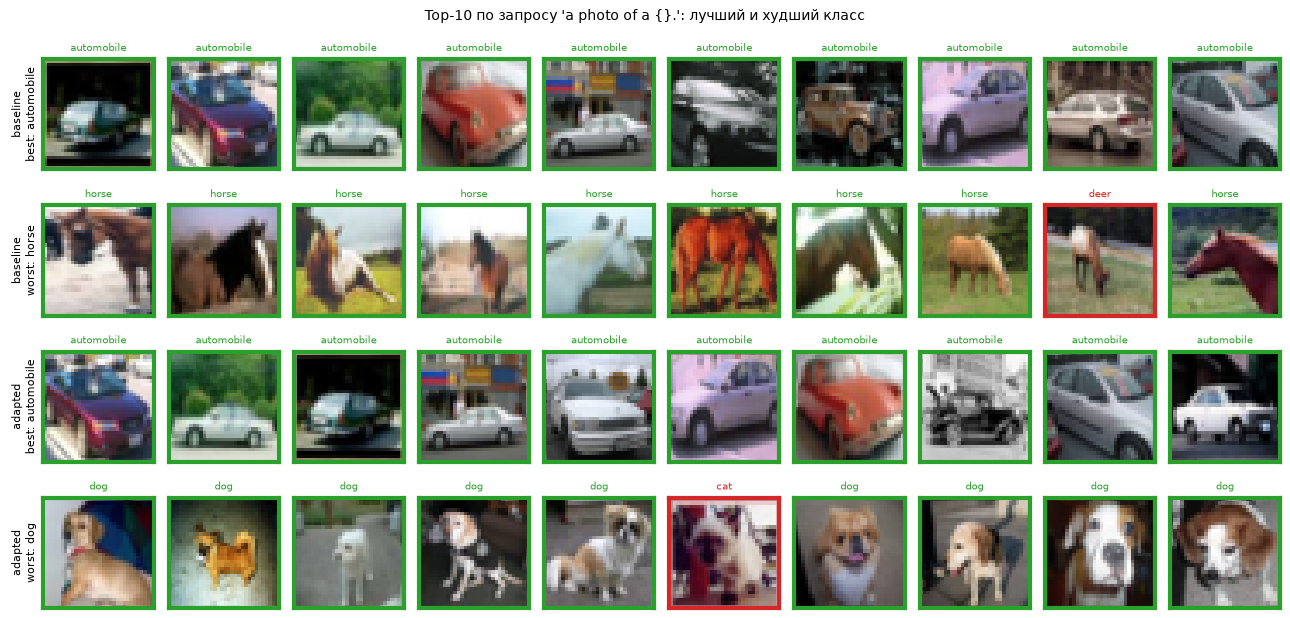

baseline  best: automobile precision@10 = 1.0, ошибки (test_idx, класс): []
baseline worst: horse      precision@10 = 0.9, ошибки (test_idx, класс): [(3962, 'deer')]
 adapted  best: automobile precision@10 = 1.0, ошибки (test_idx, класс): []
 adapted worst: dog        precision@10 = 0.9, ошибки (test_idx, класс): [(7680, 'cat')]
✔ для лучшего и худшего класса сохранены 10 индексов test и их истинные классы
✔ коллаж найденных изображений сохранён


In [13]:
# Задание 9. Лучшие и худшие результаты поиска
import matplotlib.pyplot as plt

K_TIE = 100  # при равной precision@10 (у многих классов она 1.0) порядок решает более строгая precision@100

def search_case(feats, query_embs, class_name):
    """Top-10 по запросу класса: позиции, номера CIFAR-10 test, истинные классы, сходства, релевантность."""
    c_idx = classes.index(class_name)
    pos, scores = search(query_embs[c_idx], feats, K)
    labels_found = index_labels[pos]
    return {
        "query": QUERY_TEMPLATE.format(class_name),
        "index_positions": pos.tolist(),
        "test_indices": test_idx[pos.numpy()].tolist(),
        "true_labels": [classes[l] for l in labels_found.tolist()],
        "relevant": is_relevant(labels_found, c_idx).tolist(),
        "scores": [round(float(s), 4) for s in scores],
    }

search_examples = {"k": K, "tie_break": f"precision@{K_TIE}", "variants": {}}
for variant, (ih, th) in {"baseline": variants["baseline"], "adapted": variants["adapted"]}.items():
    feats = project_images(index_feats, ih)
    protos = text_prototypes(QUERY_TEMPLATE, head=th).cpu()
    per_k, _ = retrieval_metrics(feats, index_labels, protos, K)
    per_tie, _ = retrieval_metrics(feats, index_labels, protos, K_TIE)
    # 1. Ранжирование классов: сначала precision@10, при равенстве — precision@100
    ranking = sorted(classes, key=lambda n: (per_k[n]["precision@k"], per_tie[n]["precision@k"]), reverse=True)
    best_cls, worst_cls = ranking[0], ranking[-1]
    # 2. Индексы и истинные классы найденных изображений для лучшего и худшего класса
    search_examples["variants"][variant] = {
        "ranking": [{"class": n, "precision@10": per_k[n]["precision@k"], f"precision@{K_TIE}": per_tie[n]["precision@k"]} for n in ranking],
        "best": {"class": best_cls, **search_case(feats, protos, best_cls)},
        "worst": {"class": worst_cls, **search_case(feats, protos, worst_cls)},
    }
(ARTIFACTS / "search_examples.json").write_text(json.dumps(search_examples, ensure_ascii=False, indent=2), encoding="utf-8")

# Коллаж реальных изображений CIFAR-10 test (исходные 32×32): зелёная рамка — релевантно, красная — ошибка
rows = [(v, kind) for v in search_examples["variants"] for kind in ("best", "worst")]
fig, axes = plt.subplots(len(rows), K, figsize=(K * 1.3, len(rows) * 1.6))
for r, (variant, kind) in enumerate(rows):
    case = search_examples["variants"][variant][kind]
    for j in range(K):
        ax = axes[r, j]
        ax.imshow(test_full.data[case["test_indices"][j]])
        ax.set_xticks([]); ax.set_yticks([])
        color = "tab:green" if case["relevant"][j] else "tab:red"
        for side in ax.spines.values():
            side.set_edgecolor(color); side.set_linewidth(3)
        ax.set_title(case["true_labels"][j], fontsize=7, color=color)
    axes[r, 0].set_ylabel(f"{variant}\n{kind}: {case['class']}", fontsize=8)
fig.suptitle(f"Top-{K} по запросу '{QUERY_TEMPLATE}': лучший и худший класс", fontsize=10)
fig.tight_layout()
fig.savefig(ARTIFACTS / "search_examples.png", dpi=120)
plt.show()

for variant, v in search_examples["variants"].items():
    for kind in ("best", "worst"):
        case = v[kind]
        errors = [(t, l) for t, l, ok in zip(case["test_indices"], case["true_labels"], case["relevant"]) if not ok]
        print(f"{variant:>8} {kind:>5}: {case['class']:<10} precision@10 = {sum(case['relevant']) / K:.1f}, ошибки (test_idx, класс): {errors}")
check(all(len(v[k]["test_indices"]) == K for v in search_examples["variants"].values() for k in ("best", "worst")),
      "для лучшего и худшего класса сохранены 10 индексов test и их истинные классы")
check((ARTIFACTS / "search_examples.png").exists(), "коллаж найденных изображений сохранён")

### Задание 10. Поклассовая динамика поиска

*Вес: 1 балл.*

**Постановка.** Средний показатель может скрывать ухудшение поиска для отдельных категорий.

Выполните следующие действия:
1. Повторно вычислите адаптированную precision@10 по каждому классу.
2. Сопоставьте её с исходной precision@10.

**Результат.** retrieval_deltas.json с наблюдаемыми поклассовыми изменениями.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


**Поклассовая динамика поиска**

- **Что делали**: сравнили для каждого класса precision@10, precision@100 и accuracy до и после обучения.
- **Зачем**: проверить, не скрывает ли среднее ухудшения отдельных классов. Средняя цифра может выглядеть так, будто ничего не изменилось или всё стало лучше, хотя на самом деле какой-то класс стал хуже. Ухудшение одного класса компенсируется улучшением другого, и в среднем его не видно.
- **Результат**: retrieval_deltas.json.
  - precision@10: horse стал лучше, dog хуже, среднее не изменилось;
  - precision@100: ни один класс не ухудшился;
  - accuracy: сильно выросли слабые классы (cat +6 п.п.), немного упали почти идеальные (horse −2.1 п.п.).

In [14]:
# Задание 10. Поклассовая динамика поиска
# 1. Повторно вычисляем precision@10 по каждому классу: исходные и адаптированные эмбеддинги тех же test-изображений.
#    precision@100 добавлена как более чувствительная метрика: precision@10 почти у всех классов равна 1.0
dynamics = {}
for variant, (ih, th) in {"baseline": variants["baseline"], "adapted": variants["adapted"]}.items():
    feats = project_images(index_feats, ih)
    protos = text_prototypes(QUERY_TEMPLATE, head=th).cpu()
    preds = (feats @ protos.T).argmax(1)
    dynamics[variant] = {
        "p10": retrieval_metrics(feats, index_labels, protos, K)[0],
        "p100": retrieval_metrics(feats, index_labels, protos, K_TIE)[0],
        "acc": {n: float((preds[index_labels == c] == c).float().mean()) for c, n in enumerate(classes)},
    }

# 2. Сопоставление с исходной precision@10 по каждому классу
per_class_deltas = {}
for name in classes:
    b, a = dynamics["baseline"], dynamics["adapted"]
    p10_b, p10_a = b["p10"][name]["precision@k"], a["p10"][name]["precision@k"]
    per_class_deltas[name] = {
        "precision@10_baseline": p10_b, "precision@10_adapted": p10_a, "delta_precision@10": round(p10_a - p10_b, 4),
        f"precision@{K_TIE}_baseline": b["p100"][name]["precision@k"], f"precision@{K_TIE}_adapted": a["p100"][name]["precision@k"],
        f"delta_precision@{K_TIE}": round(a["p100"][name]["precision@k"] - b["p100"][name]["precision@k"], 4),
        "accuracy_baseline": round(b["acc"][name], 4), "accuracy_adapted": round(a["acc"][name], 4),
        "delta_accuracy": round(a["acc"][name] - b["acc"][name], 4),
    }

def split_by_sign(metric):
    return {"improved": [n for n, d in per_class_deltas.items() if d[metric] > 0],
            "worsened": [n for n, d in per_class_deltas.items() if d[metric] < 0],
            "unchanged": [n for n, d in per_class_deltas.items() if d[metric] == 0]}

retrieval_deltas = {
    "k": K,
    "query_template": QUERY_TEMPLATE,
    "n_test": len(index_labels),
    "fast_dev_run": FAST_DEV_RUN,
    "per_class": per_class_deltas,
    "summary": {
        "precision@10": split_by_sign("delta_precision@10"),
        f"precision@{K_TIE}": split_by_sign(f"delta_precision@{K_TIE}"),
        "accuracy": split_by_sign("delta_accuracy"),
    },
    "mean_delta_precision@10": float(np.mean([d["delta_precision@10"] for d in per_class_deltas.values()])),
}
(ARTIFACTS / "retrieval_deltas.json").write_text(json.dumps(retrieval_deltas, ensure_ascii=False, indent=2), encoding="utf-8")

check(all(per_class_deltas[n]["precision@10_adapted"] == adapted_per_class[n]["precision@k"] for n in classes),
      "адаптированная precision@10 совпадает с заданием 8")
check(abs(retrieval_deltas["mean_delta_precision@10"] - adaptation["delta"]["mean_precision@10"]) < 1e-9,
      "среднее поклассовых изменений совпадает с delta из adaptation.json")
print(f"{'class':>10} | {'P@10 base→adapt':>16} | {'P@100 base→adapt':>17} | {'acc base→adapt':>16}")
for n, d in per_class_deltas.items():
    print(f"{n:>10} | {d['precision@10_baseline']:.2f} → {d['precision@10_adapted']:.2f} ({d['delta_precision@10']:+.2f}) | "
          f"{d[f'precision@{K_TIE}_baseline']:.2f} → {d[f'precision@{K_TIE}_adapted']:.2f} ({d[f'delta_precision@{K_TIE}']:+.2f}) | "
          f"{d['accuracy_baseline']:.3f} → {d['accuracy_adapted']:.3f} ({d['delta_accuracy']:+.3f})")
print({m: {k: v for k, v in s.items() if v} for m, s in retrieval_deltas["summary"].items()})

✔ адаптированная precision@10 совпадает с заданием 8
✔ среднее поклассовых изменений совпадает с delta из adaptation.json
     class |  P@10 base→adapt |  P@100 base→adapt |   acc base→adapt
  airplane | 1.00 → 1.00 (+0.00) | 0.99 → 0.99 (+0.00) | 0.952 → 0.971 (+0.019)
automobile | 1.00 → 1.00 (+0.00) | 1.00 → 1.00 (+0.00) | 0.980 → 0.989 (+0.009)
      bird | 1.00 → 1.00 (+0.00) | 1.00 → 1.00 (+0.00) | 0.900 → 0.935 (+0.035)
       cat | 1.00 → 1.00 (+0.00) | 0.99 → 1.00 (+0.01) | 0.851 → 0.911 (+0.060)
      deer | 1.00 → 1.00 (+0.00) | 1.00 → 1.00 (+0.00) | 0.916 → 0.965 (+0.049)
       dog | 1.00 → 0.90 (-0.10) | 0.94 → 0.98 (+0.04) | 0.923 → 0.922 (-0.001)
      frog | 1.00 → 1.00 (+0.00) | 0.99 → 1.00 (+0.01) | 0.928 → 0.971 (+0.043)
     horse | 0.90 → 1.00 (+0.10) | 0.94 → 0.97 (+0.03) | 0.986 → 0.965 (-0.021)
      ship | 1.00 → 1.00 (+0.00) | 1.00 → 1.00 (+0.00) | 0.951 → 0.988 (+0.037)
     truck | 1.00 → 1.00 (+0.00) | 1.00 → 1.00 (+0.00) | 0.981 → 0.971 (-0.010)
{'precisi

### Задание 11. Творческий бонус: композиционный запрос

*Вес: 1 дополнительный балл.*

**Постановка.** Классовое имя не исчерпывает возможности текстово-визуального поиска.

Выполните следующие действия:
1. Сформулируйте собственный не-классовый запрос и получите top-10.
2. Сохраните коллаж найденных изображений для качественной оценки, не приписывая запросу искусственных меток.

**Результат.** bonus_retrieval.png и bonus_query.json с запросом и индексами.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


Текст запроса: a photo of an animal standing in the snow.

**Творческий бонус: композиционный запрос**

- **Что делали**: искали по запросу «a photo of an animal standing in the snow.» в обеих моделях, сохранили коллаж и индексы. Метки запросу не приписывали.
- **Зачем**: проверить поиск за пределами названий классов и не испортила ли его адаптация.
- **Результат**: bonus_retrieval.png и bonus_query.json. Все найденные картинки — животные на снегу, 8 из 10 — олени. После адаптации совпали 9 из 10 картинок.

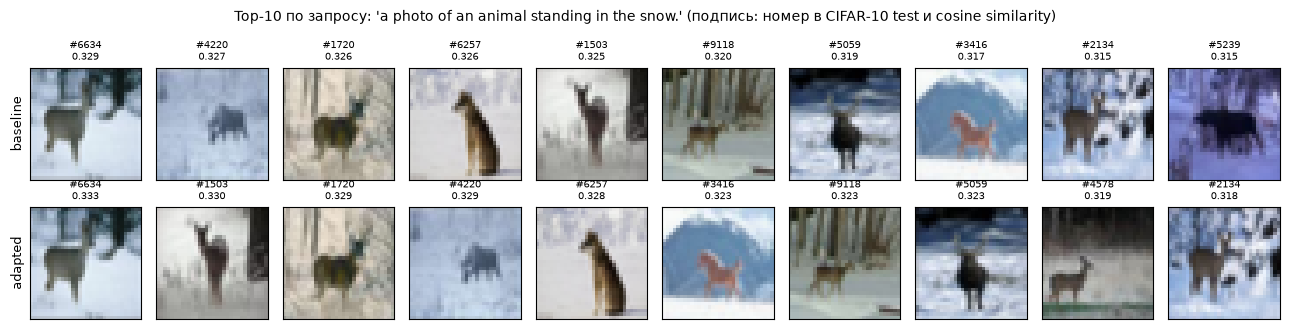

✔ по запросу найдено 10 разных изображений для обоих вариантов
✔ коллаж и запрос с индексами сохранены
baseline: test_indices = [6634, 4220, 1720, 6257, 1503, 9118, 5059, 3416, 2134, 5239]
 adapted: test_indices = [6634, 1503, 1720, 4220, 6257, 3416, 9118, 5059, 4578, 2134]
{'common_in_top10': 9, 'cifar_classes_found_baseline': ['deer', 'dog', 'horse']}


In [15]:
# Творческий бонус: композиционный запрос
# 1. Собственный не-классовый запрос: сочетание объекта, действия и сцены, которого нет среди 10 классов CIFAR-10.
#    "animal" объединяет 6 классов, а "в снегу" — свойство фона, которое в разметке не отражено вовсе
BONUS_QUERY = "a photo of an animal standing in the snow."

bonus_query = {"query": BONUS_QUERY, "k": K, "n_index": len(index_labels), "variants": {}}
for variant, (ih, th) in {"baseline": variants["baseline"], "adapted": variants["adapted"]}.items():
    feats = project_images(index_feats, ih)
    pos, scores = search(encode_query(BONUS_QUERY, head=th), feats, K)
    bonus_query["variants"][variant] = {
        "index_positions": pos.tolist(),
        "test_indices": test_idx[pos.numpy()].tolist(),
        "scores": [round(float(s), 4) for s in scores],
        # Классы CIFAR-10 сохраняются только как справка: запросу метка не приписывается и precision не считается
        "cifar_labels_for_reference": [classes[l] for l in index_labels[pos].tolist()],
    }
bonus_query["evaluation"] = "качественная: соответствие запросу оценивается визуально по bonus_retrieval.png"
(ARTIFACTS / "bonus_query.json").write_text(json.dumps(bonus_query, ensure_ascii=False, indent=2), encoding="utf-8")

# 2. Коллаж: верхняя строка — исходный CLIP, нижняя — с обученными проекциями (проверка, не потерялась ли общность)
fig, axes = plt.subplots(2, K, figsize=(K * 1.3, 2 * 1.7))
for r, (variant, res) in enumerate(bonus_query["variants"].items()):
    for j in range(K):
        ax = axes[r, j]
        ax.imshow(test_full.data[res["test_indices"][j]])
        ax.set_xticks([]); ax.set_yticks([])
        ax.set_title(f"#{res['test_indices'][j]}\n{res['scores'][j]:.3f}", fontsize=7)
    axes[r, 0].set_ylabel(variant, fontsize=9)
fig.suptitle(f"Top-{K} по запросу: '{BONUS_QUERY}' (подпись: номер в CIFAR-10 test и cosine similarity)", fontsize=10)
fig.tight_layout()
fig.savefig(ARTIFACTS / "bonus_retrieval.png", dpi=120)
plt.show()

overlap = set(bonus_query["variants"]["baseline"]["test_indices"]) & set(bonus_query["variants"]["adapted"]["test_indices"])
check(all(len(set(v["test_indices"])) == K for v in bonus_query["variants"].values()), f"по запросу найдено {K} разных изображений для обоих вариантов")
check((ARTIFACTS / "bonus_retrieval.png").exists() and (ARTIFACTS / "bonus_query.json").exists(), "коллаж и запрос с индексами сохранены")
for variant, res in bonus_query["variants"].items():
    print(f"{variant:>8}: test_indices = {res['test_indices']}")
print({"common_in_top10": len(overlap), "cifar_classes_found_baseline": sorted(set(bonus_query["variants"]["baseline"]["cifar_labels_for_reference"]))})

## Анализ результатов

Все показатели измерены в полном режиме (`FAST_DEV_RUN = False`) на отложенных реальных данных: 10 000 изображений CIFAR-10 test, по 1 000 на класс. Обучающие пары взяты только из train-сплита, поэтому test-изображения не участвовали ни в обучении, ни в выборе гиперпараметров.

**Бюджет.**
- Модель: OpenCLIP ViT-B-32 (`laion2b_s34b_b79k`), полностью заморожен.
- Признаки изображений извлекались один раз и кешировались (`test_image_features.pt`, `train_image_features.pt`). Извлечение 5 000 train-изображений заняло около 10 с на GPU.
- Обучались только две линейные проекции 512×512: 524 288 параметров. Обучение: 20 эпох по 18 батчей, Adam с lr = 1e-4, на признаках оно занимает секунды.
- Из 50 000 train-изображений использовано 5 000 стратифицированных пар (по профилю вычислений): 4 500 для обучения и 500 для выбора эпохи.

### Zero-shot классификация (`zero_shot.json`)

| Шаблон | Accuracy |
|---|---|
| `{}` (только имя класса) | 0.717 |
| `a photo of a {}.` | **0.937** |
| `a low resolution photo of a {}.` | 0.931 |
| `a blurry photo of a {}.` | 0.931 |
| `a photo of a {}, a type of object in the CIFAR-10 dataset.` | 0.934 |
| ансамбль всех шаблонов | 0.927 |

- Формулировка текста сильно влияет на результат: голое имя класса проигрывает фразе около 22 п.п. без какого-либо обучения.
- Разброс между «фразовыми» шаблонами мал (0.927–0.937, меньше 1 п.п.). Подсказки о низком разрешении и размытии не помогли, а ансамбль оказался даже немного хуже лучшего одиночного шаблона.
- Шаблоны зафиксированы до оценки, лучший по test не выбирался. Базовым заранее назначен `photo`.
- Главная ошибка модели — cat: accuracy 0.851, 82 кошки приняты за собак. Это согласуется с текстовым пространством: прототипы классов в среднем близки (средний косинус 0.77), а самая близкая пара — automobile/truck (0.88).

### Текстовый поиск (`retrieval_report.json`)

- Релевантность определена как совпадение истинного класса изображения с классом запроса.
- Исходный CLIP даёт среднюю **precision@10 = 0.99**: 9 классов из 10 получают 10/10 релевантных изображений.
- Единственная ошибка — у запроса horse: на 9-м месте олень (#3962). На коллаже `search_examples.png` видно, что это коричневый олень, пасущийся на траве: силуэт и сцена совпадают с типичным фото лошади.
- **Recall@10 = 0.0099** — значение не плохое, а почти максимальное: при 1 000 изображений класса в индексе потолок recall@10 равен 10/1000 = 0.01.

### Адаптация проекциями (`adaptation.json`)

- Лучшая эпоха выбрана по отложенной части train: эпоха 2, val accuracy 0.962 против 0.930 до обучения.
- После 2-й эпохи train loss продолжает падать (0.10 → 0.007), а val loss растёт (0.125 → 0.161), то есть начинается переобучение. Выбор эпохи по val его отсёк.

| Вариант | Accuracy | Mean precision@10 |
|---|---|---|
| baseline (замороженный CLIP) | 0.9368 | 0.990 |
| **adapted (обе проекции)** | **0.9588** | 0.990 |
| ablation: только `image_head` | 0.9525 | 1.000 |
| ablation: только `text_head` | 0.9529 | 0.990 |

- **Accuracy выросла на +2.2 п.п.** Каждая проекция по отдельности даёт примерно +1.6 п.п., вместе они дают больше, чем каждая в отдельности.
- **Средняя precision@10 не изменилась.** Метрика насыщена: при baseline 0.99 расти почти некуда, и изменения в 1 изображение из 10 лежат на уровне шума.

### Поклассовая динамика (`retrieval_deltas.json`, `search_examples.json`)

Среднее скрывает перераспределение ошибок между классами:
- **precision@10:** horse улучшился (0.9 → 1.0), dog ухудшился (1.0 → 0.9). На 6-м месте выдачи dog появилась кошка (#7680), пушистая морда которой на коллаже действительно похожа на собачью. Изменения взаимно гасятся, и среднее остаётся 0.99.
- **precision@100**, более чувствительная метрика, не ухудшилась ни у одного класса. Улучшились cat (0.99 → 1.00), dog (0.94 → 0.98), frog (0.99 → 1.00) и horse (0.94 → 0.97). Значит, ухудшение dog на P@10 — единичный сдвиг одного изображения в верхушке выдачи, а не системная деградация.
- **Поклассовая accuracy** выросла у 7 классов. Сильнее всего у слабых: cat +6.0 п.п. (0.851 → 0.911), deer +4.9, frog +4.3. Упала у horse (−2.1 п.п., 0.986 → 0.965), truck (−1.0) и dog (−0.1). Проекции «оттянули» часть пограничных изображений от классов, которые baseline распознавал почти идеально, в пользу путающихся пар.

### Композиционный запрос (`bonus_retrieval.png`, `bonus_query.json`)

- По запросу «a photo of an animal standing in the snow.» все 10 найденных изображений обоих вариантов визуально соответствуют запросу: животное на снежном или светлом фоне. Значит, CLIP понимает сочетание «объект + сцена», которого нет в разметке CIFAR.
- В выдаче преобладают олени (8 из 10): в CIFAR-10 снежные сцены типичны именно для класса deer. Поиск отражает распределение данных, а не только смысл запроса.
- После адаптации 9 из 10 изображений совпали с baseline. Одно заменилось (#5239 → #4578), и у нового изображения снег заметен хуже: животное стоит на траве. Это слабый признак того, что проекции, обученные на 10 классовых фразах, немного смещают пространство от «нецелевых» атрибутов вроде фона. Качественно общность при этом в основном сохранилась.

### Ограничения

- Использовано 10% train (5 000 пар), один seed и один запуск. Доверительные интервалы не оценивались: разница в 1 п.п. на 10 000 test-изображениях — около 100 изображений, а изменения precision@10 в 0.1 — это одно изображение.
- Валидационная часть мала (500 изображений, одно изображение = 0.2 п.п.), поэтому выбор эпохи 2 шумный: значения val accuracy на эпохах 2–10 различаются в пределах 0.6 п.п.
- Precision@10 и recall@10 почти насыщены на CIFAR-10 и плохо различают модели. Вывод об адаптации опирается в основном на accuracy и precision@100.
- Для поиска использован один шаблон запроса (`photo`), а проекции обучены именно под него. Перенос на другие формулировки не проверялся.
- Бонусный запрос оценён качественно, по одному запросу, без разметки.
- Изображения CIFAR 32×32 растягиваются до 224×224. Это отличается от данных, на которых обучался CLIP, и ограничивает как zero-shot качество, так и выводы о поиске на реальных фотографиях.

## Выводы

1. **Zero-shot CLIP без обучения даёт 93.7% accuracy на CIFAR-10, но качество зависит от формулировки текста.** Голое имя класса даёт лишь 71.7%, а фраза «a photo of a {}.» — 93.7%. Между разумными фразовыми шаблонами разница меньше 1 п.п., и ансамбль не помог (`zero_shot.json`).
2. **Текстовый поиск по классовым запросам почти идеален:** средняя precision@10 = 0.99, единственная ошибка — олень в выдаче horse (`retrieval_report.json`, `search_examples.png`). Precision@10 на CIFAR-10 насыщается и плохо подходит для сравнения моделей.
3. **Две линейные проекции поверх замороженного CLIP (524 тыс. параметров, секунды обучения) повышают accuracy с 0.937 до 0.959 (+2.2 п.п.)** без изменения средней precision@10 (`adaptation.json`). Ablation показывает, что вклад дают обе проекции: каждая по отдельности даёт около +1.6 п.п. Классовая cross-entropy против 10 прототипов позволяет обучать без ложных негативов среди одинаковых подписей. Выбор эпохи по отложенной части train остановил обучение до переобучения (лучшая эпоха — 2-я).
4. **Средний показатель скрывает поклассовые сдвиги** (`retrieval_deltas.json`). Адаптация сильнее всего помогла слабым классам (cat +6.0 п.п. accuracy), но ухудшила почти идеальные (horse −2.1 п.п.). По precision@10 horse улучшился, а dog ухудшился, и среднее осталось прежним. По precision@100 ни один класс не ухудшился, поэтому ухудшение dog — единичный случай, а не системный эффект.
5. **Мультимодальный поиск работает за пределами классовых имён:** запрос «животное в снегу» находит соответствующие сцены (`bonus_retrieval.png`). Адаптация под 10 классов почти не испортила такой поиск (9 из 10 результатов совпали), но выдача отражает перекос данных: снежные сцены в CIFAR — в основном олени.

**Итог:** для CIFAR-10 замороженный CLIP с подобранным шаблоном — сильный baseline. Лёгкая адаптация проекциями — дешёвый способ поднять классификацию на 2 п.п., но её эффект неравномерен по классам. Поэтому оценивать её нужно поклассово и чувствительными метриками, а не только средней precision@10.